In [1]:
!pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.9/39.9 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 17.5 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.31.0
    Uninstalling requests-2.31.0:
      Successfully uninstalled requests-2.31.0
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 14.0.2
    Uninstalling pyarrow-14.0.2:
      Successfully uninstalled pyarrow-14.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 24.4.1 requi

In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BigBirdTokenizer, BigBirdForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

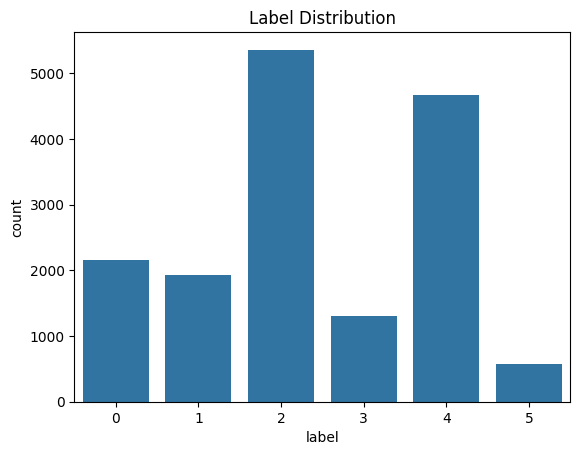

In [3]:
# Load dataset
train_data = pd.read_csv('/content/train.txt', header=None, sep=';', names=['text', 'label'])
val_data = pd.read_csv('/content//val.txt', header=None, sep=';', names=['text', 'label'])
test_data = pd.read_csv('/content//test.txt', header=None, sep=';', names=['text', 'label'])

# Data Pre-processing
label_encoder = LabelEncoder()
train_data['label'] = label_encoder.fit_transform(train_data['label'])
val_data['label'] = label_encoder.transform(val_data['label'])
test_data['label'] = label_encoder.transform(test_data['label'])

# Visualize label distribution
sns.countplot(x='label', data=train_data)
plt.title('Label Distribution')
plt.show()



In [4]:


# Tokenization
tokenizer = BigBirdTokenizer.from_pretrained('google/bigbird-roberta-base')

# Convert pandas DataFrame to Hugging Face Dataset
train_dataset = Dataset.from_pandas(train_data)
val_dataset = Dataset.from_pandas(val_data)
test_dataset = Dataset.from_pandas(test_data)

# Make sure to apply the tokenization to all datasets
def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=512)

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/846k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [5]:
from datasets import load_metric

def compute_metrics(eval_pred):
    metric = load_metric("accuracy")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)


In [6]:
from transformers import Trainer, TrainingArguments

# Model
model = BigBirdForSequenceClassification.from_pretrained('google/bigbird-roberta-base', num_labels=len(label_encoder.classes_))

# Assuming 'model', 'train_dataset', 'val_dataset', and 'tokenizer' are already set up as per your code
training_args = TrainingArguments(
    output_dir='./results',
    evaluation_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=6,
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_dir='./logs',  # Directory for storing logs
    logging_steps=10,      # Log metrics every 10 steps
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics  # Pass the compute_metrics function
)

trainer.train()




pytorch_model.bin:   0%|          | 0.00/513M [00:00<?, ?B/s]

Some weights of BigBirdForSequenceClassification were not initialized from the model checkpoint at google/bigbird-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.10/dist-packages/transformers/training_args.py:1494: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
Attention type 'block_sparse' is not possible if sequence_length: 512 <= num global tokens: 2 * config.block_size + min. num sliding tokens: 3 * config.block_size + config.num_random_blocks * config.block_size + additional buffer: config.num_random_blocks * config.block_size = 704 with config.block_size = 64, config.num_random_blocks = 3. Changing attention type to 'original_full'...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.274600,0.252493,0.929000
2,0.145900,0.191868,0.936500
3,0.163000,0.200825,0.944000
4,0.095700,0.193084,0.941500
5,0.031800,0.267375,0.935500


<ipython-input-5-8a486b30663d>:4: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  metric = load_metric("accuracy")


Epoch,Training Loss,Validation Loss,Accuracy
1,0.274600,0.252493,0.929000
2,0.145900,0.191868,0.936500
3,0.163000,0.200825,0.944000
4,0.095700,0.193084,0.941500
5,0.031800,0.267375,0.935500
6,0.129600,0.273867,0.942000


TrainOutput(global_step=12000, training_loss=0.18505189563143842, metrics={'train_runtime': 12037.8144, 'train_samples_per_second': 7.975, 'train_steps_per_second': 0.997, 'total_flos': 2.5433741131776e+16, 'train_loss': 0.18505189563143842, 'epoch': 6.0})

In [7]:
# Prediction & Evaluation
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=-1)

# True labels
y_true = test_data['label'].values

# Calculate metrics
accuracy = accuracy_score(y_true, preds)
precision = precision_score(y_true, preds, average='weighted')
f1 = f1_score(y_true, preds, average='weighted')



NameError: name 'accuracy_score' is not defined

In [ ]:
# Print metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision (Weighted): {precision:.2f}")
print(f"F1-Score (Weighted): {f1:.2f}")

# Classification Report
print(classification_report(y_true, preds, target_names=label_encoder.classes_))

# Confusion Matrix
cm = confusion_matrix(y_true, preds)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


              precision    recall  f1-score   support

       anger       0.95      0.90      0.93       275
        fear       0.86      0.96      0.91       224
         joy       0.93      0.97      0.95       695
        love       0.96      0.70      0.81       159
     sadness       0.96      0.97      0.97       581
    surprise       0.82      0.68      0.74        66

    accuracy                           0.93      2000
   macro avg       0.91      0.87      0.88      2000
weighted avg       0.93      0.93      0.93      2000



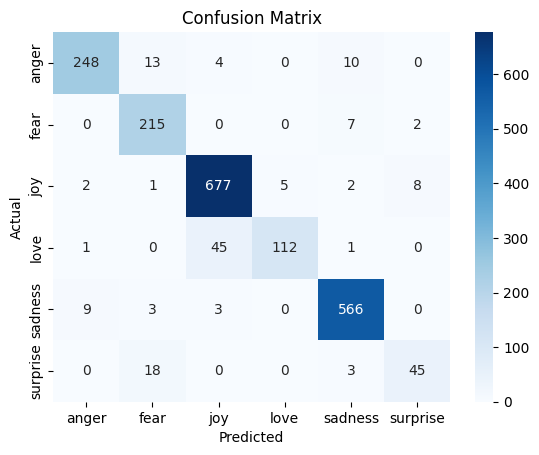

In [8]:



# Prediction & Evaluation
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=-1)

# Classification Report
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(test_data['label'], preds, target_names=label_encoder.classes_))

# Confusion Matrix
cm = confusion_matrix(test_data['label'], preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


In [11]:
# Save model


model.save_pretrained('/content/drive/MyDrive/model_nlp/bigbird_model')
tokenizer.save_pretrained('/content/drive/MyDrive/model_nlp/bigbird_model')

('/content/drive/MyDrive/model_nlp/bigbird_model/tokenizer_config.json',
 '/content/drive/MyDrive/model_nlp/bigbird_model/special_tokens_map.json',
 '/content/drive/MyDrive/model_nlp/bigbird_model/spiece.model',
 '/content/drive/MyDrive/model_nlp/bigbird_model/added_tokens.json')

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
